# Simulación de Demanda y Valor Subjetivo del Tiempo (VST) - Tren Rápido Barcelona-Valencia (BV)

Este notebook traduce el script de R a Python para simular la elección modal con 4 alternativas (Auto, Bus, Tren, Avión) y el modo pivote (Tren Rápido) para el corredor Barcelona - Valencia.


## 1. Importación de Librerías


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Fijar semilla para reproducibilidad
np.random.seed(42)


## 2. Configuración de Parámetros e Inicialización


In [2]:
a = 1500  # Personas que responden la encuesta
r = 100   # Repeticiones del ejercicio de estimar parámetros
VSTi = 0.20  # Valor subjetivo del tiempo inicial (Euro por minuto)

VSTT = np.zeros(r)


## 3. Bucle de Simulación Monte Carlo (Estimación VST)


In [3]:
for f in range(r):
    alpha = np.full(a, -0.1355)  # Parámetro asociado a la tarifa
    beta = VSTi * alpha          # Parámetro asociado al tiempo
    
    precioRP = np.zeros((a, 4))
    tiempoRP = np.zeros((a, 4))
    cteModal = np.zeros((a, 4))
    
    precio = np.zeros((a, 2))
    tiempo = np.zeros((a, 2))
    
    epsilon = np.zeros((a, 4))
    epsilon2 = np.zeros((a, 4))
    epsilon3 = np.zeros((a, 4))
    
    # Simulación de datos RP (4 alternativas: Auto, Bus, Tren, Avión)
    precioRP[:, 0] = np.random.uniform(45, 55, a)  # Auto
    precioRP[:, 1] = np.random.uniform(30, 35, a)  # Bus
    precioRP[:, 2] = np.random.uniform(35, 40, a)  # Tren
    precioRP[:, 3] = np.random.uniform(65, 85, a)  # Avión
    
    tiempoRP[:, 0] = np.random.normal(60 * 4, 10, a)     # Auto
    tiempoRP[:, 1] = np.random.normal(60 * 4, 25, a)     # Bus
    tiempoRP[:, 2] = np.random.normal(60 * 3.5, 25, a)   # Tren
    tiempoRP[:, 3] = np.random.normal(60 * 3.25, 30, a)  # Avión
    
    cteModal[:, 0] = 0.0   # Auto
    cteModal[:, 1] = -4.5  # Bus
    cteModal[:, 2] = -3.8  # Tren
    cteModal[:, 3] = 0.5   # Avión
    
    # Errores Gumbel (Logit) para 4 alternativas
    for i in range(4):
        epsilon[:, i] = -np.log(-np.log(np.random.uniform(0, 1, a)))
        epsilon2[:, i] = -np.log(-np.log(np.random.uniform(0, 1, a)))
        epsilon3[:, i] = -np.log(-np.log(np.random.uniform(0, 1, a)))
        
    # Simulación de utilidades RP
    URP = np.zeros((a, 4))
    for i in range(a):
        for j in range(4):
            URP[i, j] = cteModal[i, j] + beta[i] * tiempoRP[i, j] + alpha[i] * precioRP[i, j] + epsilon[i, j]
            
    YRP = np.argmax(URP, axis=1) + 1
    
    # Tasa de mejora de la alternativa pivote (SP) para 4 alternativas
    tasa = [0.54, 0.64, 0.56, 0.2]  # [auto, bus, tren, avion]
    
    for i in range(a):
        j_chosen = YRP[i] - 1
        precio[i, 0] = precioRP[i, j_chosen]
        tiempo[i, 0] = tiempoRP[i, j_chosen]
        precio[i, 1] = precioRP[i, j_chosen] * (1 + tasa[j_chosen])  # Tren bala
        tiempo[i, 1] = tiempoRP[i, j_chosen] * (1 - tasa[j_chosen])  # Tren bala
        
    # Simulación de utilidades pivote (SP)
    U = np.zeros((a, 2))
    for i in range(a):
        for j in range(2):
            U[i, j] = beta[i] * tiempo[i, j] + alpha[i] * precio[i, j] + epsilon2[i, j]
            
    Y = np.argmax(U, axis=1) + 1
    
    # Estimación del modelo OLS
    tiempoF = tiempo[:, 1] - tiempo[:, 0]
    precioF = precio[:, 1] - precio[:, 0]
    
    X_design = np.column_stack((np.ones(a), tiempoF, precioF))
    model = sm.OLS(Y, X_design)
    results = model.fit()
    coef1 = results.params
    
    VST = coef1[1] / coef1[2]
    VSTT[f] = VST

VSTm = round(np.mean(VSTT), 2)
print(f"VST Medio estimado: {VSTm}")


VST Medio estimado: 0.2


## 4. Análisis de Partición Modal y Probabilidades SP


In [4]:
cteModalSP = [coef1[0], 0.0]
USP = np.zeros((a, 2))
for i in range(a):
    for j in range(2):
        USP[i, j] = cteModalSP[j] + coef1[1] * tiempo[i, j] + coef1[2] * precio[i, j] + epsilon3[i, j]

YSP = np.argmax(USP, axis=1) + 1

cambioautoTrenbala = np.zeros(a)
cambiobusTrenbala = np.zeros(a)
cambiotrenTrenbala = np.zeros(a)
cambioavionTrenbala = np.zeros(a)

usuariosauto = np.zeros(a)
usuariosbus = np.zeros(a)
usuariostren = np.zeros(a)
usuariosavion = np.zeros(a)

for i in range(a):
    if YRP[i] == 1 and YSP[i] == 2:
        cambioautoTrenbala[i] = 1
    if YRP[i] == 2 and YSP[i] == 2:
        cambiobusTrenbala[i] = 1
    if YRP[i] == 3 and YSP[i] == 2:
        cambiotrenTrenbala[i] = 1
    if YRP[i] == 4 and YSP[i] == 2:
        cambioavionTrenbala[i] = 1
        
    if YRP[i] == 1:
        usuariosauto[i] = 1
    elif YRP[i] == 2:
        usuariosbus[i] = 1
    elif YRP[i] == 3:
        usuariostren[i] = 1
    elif YRP[i] == 4:
        usuariosavion[i] = 1

sum_auto = np.sum(usuariosauto)
sum_bus = np.sum(usuariosbus)
sum_tren = np.sum(usuariostren)
sum_avion = np.sum(usuariosavion)
total_usuarios = sum_bus + sum_auto + sum_tren + sum_avion

CambioAutoTren = round(np.sum(cambioautoTrenbala) / sum_auto, 2)
CambioBusTren = round(np.sum(cambiobusTrenbala) / sum_bus, 2)
CambioTrenTren = round(np.sum(cambiotrenTrenbala) / sum_tren, 2)
CambioAvionTren = round(np.sum(cambioavionTrenbala) / sum_avion, 2)

usuarioautoPC = sum_auto / total_usuarios
usuariobusPC = sum_bus / total_usuarios
usuariotrenPC = sum_tren / total_usuarios
usuarioavionPC = sum_avion / total_usuarios

ParticionModalRP = [round(usuarioautoPC, 2), round(usuariobusPC, 2), round(usuariotrenPC, 2), round(usuarioavionPC, 2)]

UsuarioSPAuto = usuarioautoPC * (1 - CambioAutoTren)
UsuarioSPBus = usuariobusPC * (1 - CambioBusTren)
UsuarioSPAvion = usuarioavionPC * (1 - CambioAvionTren)
UsuarioSPTren = usuariotrenPC * (1 - CambioTrenTren)
UsuarioSPTrenR = 1 - (UsuarioSPAuto + UsuarioSPBus + UsuarioSPAvion + UsuarioSPTren)

ParticionModalSP = [round(UsuarioSPAuto, 2), round(UsuarioSPBus, 2), round(UsuarioSPTren, 2), round(UsuarioSPAvion, 2), round(UsuarioSPTrenR, 2)]

EtiquetasRP = ["Auto", "Bus", "Tren", "Avión"]
EtiquetasSP = ["Auto", "Bus", "Tren", "Avión", "Tren Rápido"]

print("Partición Modal RP:", ParticionModalRP)
print("Partición Modal SP:", ParticionModalSP)
print("Media VSTT:", np.mean(VSTT))


Partición Modal RP: [np.float64(0.55), np.float64(0.09), np.float64(0.2), np.float64(0.17)]
Partición Modal SP: [np.float64(0.45), np.float64(0.07), np.float64(0.16), np.float64(0.14), np.float64(0.19)]
Media VSTT: 0.19998337819148054


## 5. Visualización de Resultados


/var/folders/db/bt0lzwjx41z9b19jjkz44b400000gn/T/ipykernel_25385/1636005611.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(VSTT, vert=True, patch_artist=True)


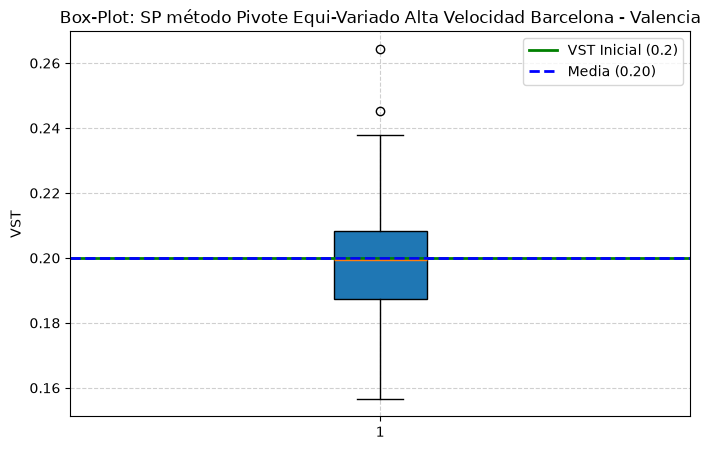

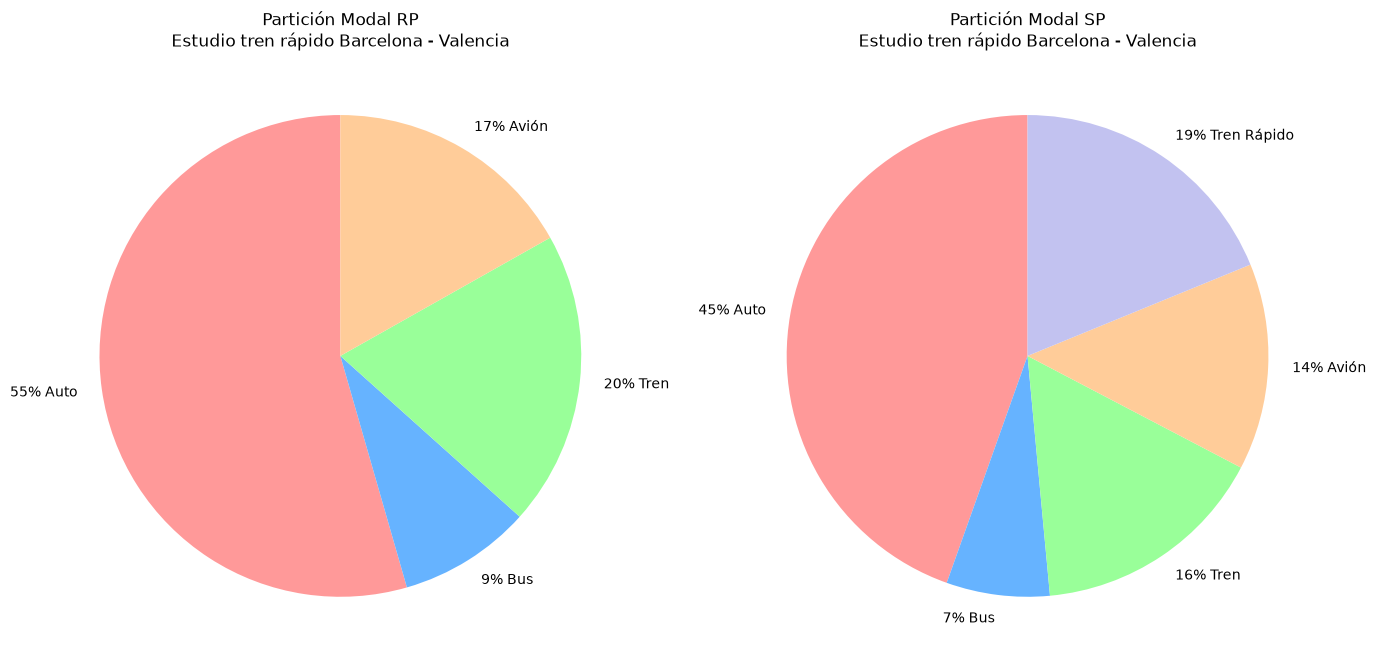

In [5]:
# Gráfico Box-Plot del VST
plt.figure(figsize=(8, 5))
plt.boxplot(VSTT, vert=True, patch_artist=True)
plt.axhline(y=VSTi, color='green', linestyle='-', linewidth=2, label=f'VST Inicial ({VSTi})')
media = np.mean(VSTT)
plt.axhline(y=media, color='blue', linestyle='--', linewidth=2, label=f'Media ({media:.2f})')
plt.ylabel('VST')
plt.title('Box-Plot: SP método Pivote Equi-Variado Alta Velocidad Barcelona - Valencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Gráficos de Partición Modal (Pie Charts)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].pie(ParticionModalRP, labels=[f'{int(p*100)}% {e}' for p, e in zip(ParticionModalRP, EtiquetasRP)], 
            startangle=90, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99'])
axes[0].set_title('Partición Modal RP\nEstudio tren rápido Barcelona - Valencia')

axes[1].pie(ParticionModalSP, labels=[f'{int(p*100)}% {e}' for p, e in zip(ParticionModalSP, EtiquetasSP)], 
            startangle=90, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0'])
axes[1].set_title('Partición Modal SP\nEstudio tren rápido Barcelona - Valencia')

plt.tight_layout()
plt.show()
